# Kickstarter Project Success: EDA and Modelling

Can we predict whether a Kickstarter project will be successfully funded,
using only information known before the campaign starts?

## How to Run This Notebook

1. Install the environment from the project root with `uv sync`, then select the `.venv` (Python 3.13) kernel.
2. Download the dataset [Kickstarter Projects](https://www.kaggle.com/datasets/kemical/kickstarter-projects) from Kaggle and place `ks-projects-201801.csv` in the `data/` folder (or run `uv run kickstarter-download`). The data is not stored in this repository.
3. Run the notebook top to bottom (**Restart** → **Run All**); it finds `data/` and `models/` from the repository root or from `notebooks/`. The full run takes a few minutes; the final model is saved to `models/kickstarter_success_model.joblib`.

## Summary

- **Goal:** estimate the probability that a Kickstarter project gets funded, using only information available before launch, so that creators can assess their chances.
- **Data:** 372,293 finished projects launched 2009 to early 2018; 36% were successfully funded.
- **Key drivers:** the funding goal (smaller goals succeed far more often), the category (Dance, Theater and Comics do best; Technology, Journalism and Crafts worst) and the campaign duration (for every goal size, the exact 30-day default is below 15-29 and 31-44 days, and 60 days is the weakest).
- **Result:** a tuned Gradient Boosting model gives **well-calibrated probabilities** (ROC-AUC **0.754**, Brier score **0.189** on the held-out test set). As a yes/no label it reaches **F1 = 0.619**, compared with F1 = 0.524 for a simple goal-based rule. On a time-based check (trained before 2016, tested from 2016) the ranking holds (ROC-AUC 0.757).
- **Limits:** the model relies mostly on category and goal; campaign content (video, rewards, promotion) is not in the data, and the associations it finds are not proof of cause and effect.

## Setup

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    TunedThresholdClassifierCV,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.0


In [2]:
# Works whether the notebook runs from the repository root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "ks-projects-201801.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} not found. Download it from Kaggle (see 'How to Run') "
        "and run the notebook from the repository root."
    )

kickstarter = pd.read_csv(DATA_PATH)
kickstarter.head()

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


## First Look at the Data

In [3]:
kickstarter.info()

<class 'pandas.DataFrame'>
RangeIndex: 378661 entries, 0 to 378660
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   ID                378661 non-null  int64  
 1   name              378657 non-null  str    
 2   category          378661 non-null  str    
 3   main_category     378661 non-null  str    
 4   currency          378661 non-null  str    
 5   deadline          378661 non-null  str    
 6   goal              378661 non-null  float64
 7   launched          378661 non-null  str    
 8   pledged           378661 non-null  float64
 9   state             378661 non-null  str    
 10  backers           378661 non-null  int64  
 11  country           378661 non-null  str    
 12  usd pledged       374864 non-null  float64
 13  usd_pledged_real  378661 non-null  float64
 14  usd_goal_real     378661 non-null  float64
dtypes: float64(5), int64(2), str(8)
memory usage: 77.0 MB


In [4]:
print("Fully duplicated rows:", kickstarter.duplicated().sum())
print("Duplicated project IDs:", kickstarter["ID"].duplicated().sum())

Fully duplicated rows: 0
Duplicated project IDs: 0


In [5]:
# The invalid country code 'N,0"' marks corrupted records: check that these are
# exactly the rows without a 'usd pledged' value, and look at their state
invalid_country_raw = kickstarter["country"] == 'N,0"'
print("Rows with country 'N,0\"':", invalid_country_raw.sum())
print(
    "Same rows as the missing 'usd pledged' values:",
    (invalid_country_raw == kickstarter["usd pledged"].isna()).all(),
)
kickstarter.loc[invalid_country_raw, "state"].value_counts()

Rows with country 'N,0"': 3797
Same rows as the missing 'usd pledged' values: True


state
undefined     3562
successful     105
failed         105
canceled        22
suspended        2
live             1
Name: count, dtype: int64

### Summary of First Checks

- The dataset contains **378,661 projects** and **15 columns**.
- **Missing values** appear in only two columns:
  - `name`: 4 projects have no name. This is negligible; we will handle these rows if we use the name as a feature.
  - `usd pledged`: 3,797 missing values. This column is only known after the campaign ends (leakage), so it will be dropped anyway.
- There are **no fully duplicated rows** and **no duplicated project IDs**, so every row is a unique project.
- The date columns `deadline` and `launched` are stored as **text** and will need to be converted to datetime before we can compute features such as campaign duration.
- The `state` column contains more than just `successful` and `failed` (for example `canceled`), so the target variable must be defined explicitly.

## Define the Target Variable

In [6]:
kickstarter["state"].value_counts()

state
failed        197719
successful    133956
canceled       38779
undefined       3562
live            2799
suspended       1846
Name: count, dtype: int64

In [7]:
# Drop projects whose outcome is unknown
kickstarter = kickstarter[~kickstarter["state"].isin(["live", "undefined"])].copy()

# Target: 1 = successful, 0 = not funded (failed, canceled, suspended)
kickstarter["success"] = (kickstarter["state"] == "successful").astype(int)

print("Projects kept:", len(kickstarter))
kickstarter["success"].value_counts(normalize=True)

Projects kept: 372300


success
0    0.640193
1    0.359807
Name: proportion, dtype: float64

In [8]:
# Edge case: canceled projects that had already reached their goal
canceled = kickstarter["state"] == "canceled"
reached_goal = kickstarter["usd_pledged_real"] >= kickstarter["usd_goal_real"]
print("Canceled projects that had reached their goal:", (canceled & reached_goal).sum())

Canceled projects that had reached their goal: 698


### Target Decision

The `state` column has six values. We define a binary target `success`:

| state | projects | treatment |
|---|---|---|
| successful | 133,956 | `success = 1` |
| failed | 197,719 | `success = 0` |
| canceled | 38,779 | `success = 0` (not funded) |
| suspended | 1,846 | `success = 0` (not funded) |
| live | 2,799 | dropped (outcome unknown) |
| undefined | 3,562 | dropped (outcome unknown) |

Our question is therefore: **will a project get funded, or not get funded for any reason?**
Canceled and suspended projects never received the money, so from a creator's point of view they are not funded.

After dropping projects with an unknown outcome, **372,300 projects** remain: **36.0% successful** and **64.0% not funded**.
The classes are moderately imbalanced, so accuracy alone would be misleading (always predicting "not funded" already gives 64%).

**Edge cases:** 698 canceled projects had already reached their goal. They were stopped by their creators (often to relaunch) and are counted as not funded, which is correct from the money's point of view but adds a little noise. Relaunches of the same idea can also appear more than once in the data; since project names are not used as text features, this has a negligible effect.

## Drop Leakage Columns

Some columns are only known **after** the campaign has ended, so they would give away the answer (target leakage).
A creator who wants a prediction **before** launching does not have this information yet.

- `pledged`, `usd pledged`, `usd_pledged_real`: money collected; if it reaches the goal, the project is successful by definition.
- `backers`: number of supporters, only final at the end of the campaign.
- `state`: the original outcome; our target `success` is derived from it.

In [9]:
leakage_cols = ["pledged", "usd pledged", "usd_pledged_real", "backers", "state"]
kickstarter = kickstarter.drop(columns=leakage_cols)
kickstarter.columns.tolist()

['ID',
 'name',
 'category',
 'main_category',
 'currency',
 'deadline',
 'goal',
 'launched',
 'country',
 'usd_goal_real',
 'success']

## Exploratory Data Analysis

### Success Rate by Main Category

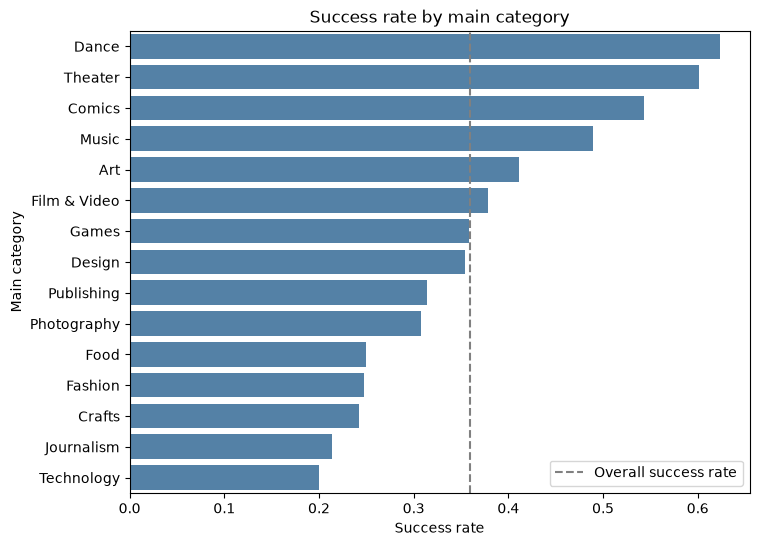

,success_rate,projects,median_goal_usd
main_category,,,
Dance,0.624,3749,3300.00
Theater,0.601,10871,3291.77
Comics,0.544,10743,3500.00
Music,0.490,49403,4000.00
Art,0.412,27959,3000.00
Film & Video,0.379,62399,7000.00
Games,0.358,34943,8000.00
Design,0.354,29763,10000.00
Publishing,0.314,39113,5000.00


In [10]:
overall_rate = kickstarter["success"].mean()

category_stats = (
    kickstarter.groupby("main_category")
    .agg(
        success_rate=("success", "mean"),
        projects=("success", "size"),
        median_goal_usd=("usd_goal_real", "median"),
    )
    .sort_values("success_rate", ascending=False)
)

plt.figure(figsize=(8, 6))
sns.barplot(
    x=category_stats["success_rate"],
    y=category_stats.index,
    color="steelblue",
)
plt.axvline(overall_rate, color="grey", linestyle="--", label="Overall success rate")
plt.xlabel("Success rate")
plt.ylabel("Main category")
plt.title("Success rate by main category")
plt.legend()
plt.show()

category_stats.round(3)

**Takeaway:** Success rates differ strongly by category. Creative and community-driven projects such as **Dance (62%)**, **Theater (60%)** and **Comics (54%)** are funded far more often than the overall rate of 36%.
Product-oriented categories such as **Technology (20%)**, **Journalism (21%)**, **Crafts (24%)**, **Fashion** and **Food (25%)** perform worst. One hypothesis is that these projects ask for larger goals, which we check next.
Note that Dance is a small category (about 3,700 projects), while Technology is large (about 32,000), so the category is likely an important feature. The table above also lists the median goal of each category.

### Success Rate by Funding Goal

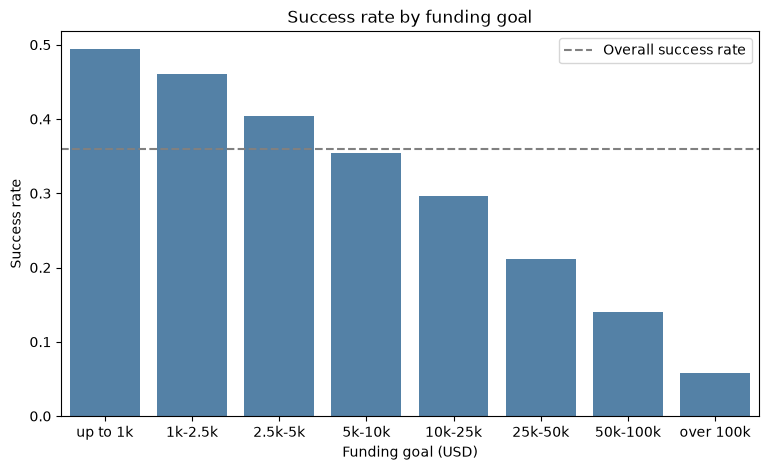

,mean,size
usd_goal_real,,
up to 1k,0.494,60449
1k-2.5k,0.460,52221
2.5k-5k,0.404,70173
5k-10k,0.354,66046
10k-25k,0.296,62683
25k-50k,0.211,31931
50k-100k,0.140,16217
over 100k,0.058,12580


In [11]:
# pd.cut uses right-closed bins, so "up to 1k" includes goals of exactly 1,000 USD
goal_bins = [0, 1_000, 2_500, 5_000, 10_000, 25_000, 50_000, 100_000, float("inf")]
goal_labels = [
    "up to 1k",
    "1k-2.5k",
    "2.5k-5k",
    "5k-10k",
    "10k-25k",
    "25k-50k",
    "50k-100k",
    "over 100k",
]

goal_group = pd.cut(kickstarter["usd_goal_real"], bins=goal_bins, labels=goal_labels)
success_by_goal = kickstarter.groupby(goal_group, observed=True)["success"].agg(
    ["mean", "size"]
)

plt.figure(figsize=(9, 5))
sns.barplot(x=success_by_goal.index, y=success_by_goal["mean"], color="steelblue")
plt.axhline(overall_rate, color="grey", linestyle="--", label="Overall success rate")
plt.xlabel("Funding goal (USD)")
plt.ylabel("Success rate")
plt.title("Success rate by funding goal")
plt.legend()
plt.show()

success_by_goal.round(3)

In [12]:
# Very small goals are often tests or joke projects: do they drive the headline?
tiny_goal = kickstarter["usd_goal_real"] <= 10
print("Projects with a goal of 10 USD or less:", tiny_goal.sum())
print("Their success rate:", round(kickstarter.loc[tiny_goal, "success"].mean(), 3))

up_to_1k = kickstarter["usd_goal_real"] <= 1_000
at_least_100 = kickstarter["usd_goal_real"] >= 100
print(
    "Success rate, goals up to 1k:",
    round(kickstarter.loc[up_to_1k, "success"].mean(), 3),
)
print(
    "Success rate, goals 100 USD to 1k:",
    round(kickstarter.loc[up_to_1k & at_least_100, "success"].mean(), 3),
)

Projects with a goal of 10 USD or less: 1143
Their success rate: 0.626
Success rate, goals up to 1k: 0.494
Success rate, goals 100 USD to 1k: 0.492


**Takeaway:** The higher the funding goal, the lower the chance of success. The success rate drops steadily from **49% for goals up to 1k USD** to only **6% for goals above 100k USD**.
Because each goal group is roughly twice as large as the previous one, success falls by a similar amount every time the goal doubles. This suggests a **logarithmic** relationship, so we will use the log of the goal as a feature.

**Very small goals:** 1,143 projects ask for 10 USD or less (often tests or jokes) and 63% of them are funded. They do not drive the headline: without goals under 100 USD, the success rate for goals up to 1k USD is still 49% (49.2% instead of 49.4%).

The category table above already showed that Technology has a median goal of 20k USD, against about 3.3k USD for Dance and Theater. However, Crafts has the lowest median goal (about 2.3k USD) and still performs poorly, so the category has an effect of its own.
Note: a lower goal raises the chance of success, but it also caps the money a project can raise.

#### Who Funds Small Creative Projects? (Explanation Only)

One possible reason why Dance, Theater and Music do so well is that small projects in these categories are funded by the creator's own circle: friends, family and the local audience. We check two things. First, does the category gap remain **within the same goal range**? Second, what do the **backers** of funded projects look like?
`backers` is only known after the campaign, so we reload it here for this explanation only. It is **not** used as a model input.

In [13]:
backer_info = pd.read_csv(DATA_PATH, usecols=["ID", "backers", "usd_pledged_real"])
circle = kickstarter[["ID", "main_category", "usd_goal_real", "success"]].merge(
    backer_info, on="ID", how="left"
)
circle["goal_range"] = pd.cut(
    circle["usd_goal_real"],
    bins=[0, 1_000, 5_000, 25_000, float("inf")],
    labels=["up to 1k", "1k-5k", "5k-25k", "over 25k"],
)

# Does the category gap remain for the same goal range?
category_by_goal = circle.pivot_table(
    index="main_category",
    columns="goal_range",
    values="success",
    aggfunc="mean",
    observed=True,
).sort_values("1k-5k", ascending=False)
print("Success rate by main category and goal range:")
print(category_by_goal.round(2))

# Backers of funded projects with a goal of 1k-5k USD
funded_small = circle[(circle["success"] == 1) & (circle["goal_range"] == "1k-5k")].copy()
funded_small["usd_per_backer"] = funded_small["usd_pledged_real"] / funded_small[
    "backers"
].where(funded_small["backers"] > 0)
backer_stats = (
    funded_small.groupby("main_category")
    .agg(
        projects=("ID", "size"),
        median_backers=("backers", "median"),
        median_usd_per_backer=("usd_per_backer", "median"),
    )
    .sort_values("median_backers")
)
print("\nFunded projects with a goal of 1k-5k USD:")
print(backer_stats.round(1))
print(
    "\nAll categories: median backers",
    funded_small["backers"].median(),
    "| median USD per backer",
    round(funded_small["usd_per_backer"].median(), 1),
)

Success rate by main category and goal range:
goal_range     up to 1k  1k-5k  5k-25k  over 25k
main_category                                   
Dance              0.66   0.69    0.56      0.13
Theater            0.72   0.68    0.48      0.21
Comics             0.72   0.56    0.45      0.28
Music              0.54   0.54    0.45      0.18
Film & Video       0.51   0.46    0.36      0.18
Art                0.52   0.45    0.32      0.11
Games              0.54   0.44    0.33      0.18
Design             0.54   0.43    0.35      0.21
Publishing         0.47   0.34    0.25      0.12
Food               0.32   0.31    0.28      0.10
Photography        0.42   0.30    0.28      0.18
Technology         0.40   0.26    0.20      0.14
Journalism         0.30   0.24    0.18      0.10
Fashion            0.34   0.24    0.25      0.13
Crafts             0.38   0.20    0.15      0.05

Funded projects with a goal of 1k-5k USD:
               projects  median_backers  median_usd_per_backer
main_category  

**Takeaway:** The category gap remains for the same goal range. With a goal of 1k-5k USD, **Dance (69%)** and **Theater (68%)** are funded far more often than **Technology (26%)** or **Crafts (20%)**, so the category effect is not only a goal effect.
The backers differ too. Funded 1k-5k USD projects in Dance, Theater, Film & Video and Music had **few but generous backers** (median 43-53 backers, about 60-75 USD each). In Games and Comics they had **many small backers** (98-141, about 40 USD each), which looks more like strangers pre-ordering a product.
This fits the idea that small creative projects are often carried by the creator's **own circle**. It is only a **possible explanation**: the data does not say who the backers are, and few, generous backers are typical for funded small projects in most categories (median 56 backers, 60 USD each). The model cannot see the size of a creator's network, which is one reason why it cannot do much better.

### Campaign Duration

We convert the date columns to datetime and compute the campaign duration in days.

In [14]:
kickstarter["launched"] = pd.to_datetime(kickstarter["launched"])
kickstarter["deadline"] = pd.to_datetime(kickstarter["deadline"])

# launched includes a time of day, deadline does not, so compare calendar dates only
kickstarter["duration_days"] = (
    kickstarter["deadline"] - kickstarter["launched"].dt.normalize()
).dt.days

kickstarter[["launched", "deadline", "duration_days"]].describe()

,launched,deadline,duration_days
count,372300,372300,372300.000000
mean,2014-09-17 17:03:48.487948,2014-10-21 14:26:28.061241,34.456414
min,1970-01-01 01:00:00,2009-05-03 00:00:00,1.000000
25%,2013-04-24 23:55:25.500000,2013-05-27 00:00:00,30.000000
50%,2014-11-25 00:17:19.500000,2014-12-31 00:00:00,30.000000
75%,2016-03-16 23:01:33.250000,2016-04-20 00:00:00,37.000000
max,2018-01-02 03:05:10,2018-02-24 00:00:00,16739.000000
std,NaN,NaN,66.448829


In [15]:
invalid_launch = kickstarter[kickstarter["launched"].dt.year == 1970]
print("Projects with launch date 1970:", len(invalid_launch))
invalid_launch[
    ["name", "main_category", "launched", "deadline", "duration_days", "success"]
]

Projects with launch date 1970: 7


,name,main_category,launched,deadline,duration_days,success
2842,Salt of the Earth: A Dead Sea Movie (Canceled),Film & Video,1970-01-01 01:00:00,2010-09-15,14867,0
48147,1st Super-Size Painting - Social Network Owned...,Art,1970-01-01 01:00:00,2010-08-14,14835,0
75397,"""ICHOR"" (Canceled)",Film & Video,1970-01-01 01:00:00,2010-05-21,14750,0
94579,"Support Solo Theater! Help ""Ungrateful Daughte...",Theater,1970-01-01 01:00:00,2010-06-01,14761,0
247913,"Help RIZ Make A Charity Album: 8 Songs, 8 Caus...",Music,1970-01-01 01:00:00,2010-05-04,14733,0
273779,Identity Communications Infographic (Canceled),Design,1970-01-01 01:00:00,2010-04-10,14709,0
319002,Student Auditions Music 2015,Publishing,1970-01-01 01:00:00,2015-10-31,16739,0


In [16]:
# Drop projects with an invalid launch date (1970 = missing timestamp)
kickstarter = kickstarter.drop(index=invalid_launch.index)

print("Projects remaining:", len(kickstarter))
kickstarter["duration_days"].describe()

Projects remaining: 372293


count    372293.000000
mean         34.173968
std          12.792708
min           1.000000
25%          30.000000
50%          30.000000
75%          37.000000
max          92.000000
Name: duration_days, dtype: float64

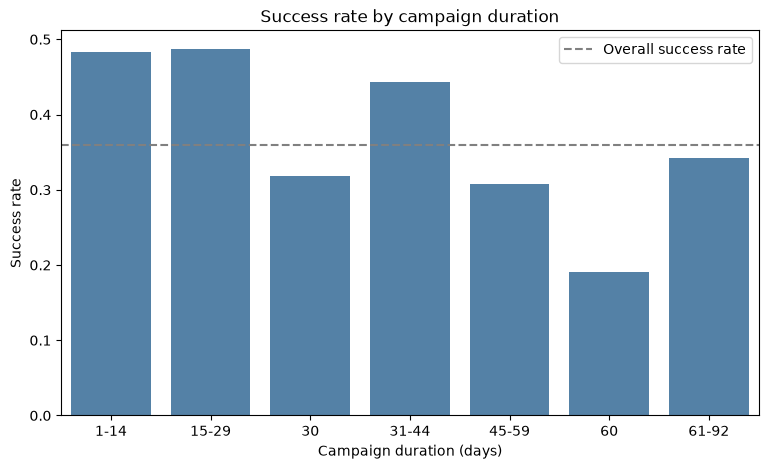

,mean,size
duration_days,,
1-14,0.483118,13417
15-29,0.487341,55177
30,0.318837,166483
31-44,0.443156,65909
45-59,0.307987,33128
60,0.190224,32714
61-92,0.341995,5465


In [17]:
duration_bins = [0, 14, 29, 30, 44, 59, 60, 92]
duration_labels = ["1-14", "15-29", "30", "31-44", "45-59", "60", "61-92"]

duration_group = pd.cut(
    kickstarter["duration_days"], bins=duration_bins, labels=duration_labels
)
success_by_duration = kickstarter.groupby(duration_group, observed=True)["success"].agg(
    ["mean", "size"]
)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=success_by_duration.index, y=success_by_duration["mean"], color="steelblue"
)
plt.axhline(overall_rate, color="grey", linestyle="--", label="Overall success rate")
plt.xlabel("Campaign duration (days)")
plt.ylabel("Success rate")
plt.title("Success rate by campaign duration")
plt.legend()
plt.show()

success_by_duration

Short campaigns could simply be projects with small goals. To separate the two effects, we look at the success rate by duration **within** each goal range.

In [18]:
goal_range = pd.cut(
    kickstarter["usd_goal_real"],
    bins=[0, 1_000, 5_000, 25_000, float("inf")],
    labels=["up to 1k", "1k-5k", "5k-25k", "over 25k"],
)

print("Median goal (USD) by duration:")
print(kickstarter.groupby(duration_group, observed=True)["usd_goal_real"].median())

kickstarter.pivot_table(
    index=goal_range,
    columns=duration_group,
    values="success",
    aggfunc="mean",
    observed=True,
).round(3)

Median goal (USD) by duration:
duration_days
1-14     1200.00
15-29    3500.00
30       5500.00
31-44    8000.00
45-59    8132.27
60       9750.00
61-92    5000.00
Name: usd_goal_real, dtype: float64


duration_days,1-14,15-29,30,31-44,45-59,60,61-92
usd_goal_real,,,,,,,
up to 1k,0.593,0.590,0.428,0.569,0.463,0.350,0.485
1k-5k,0.457,0.538,0.380,0.537,0.389,0.261,0.404
5k-25k,0.280,0.417,0.293,0.431,0.294,0.178,0.279
over 25k,0.073,0.215,0.139,0.261,0.151,0.057,0.077


**Takeaway:** In the raw numbers, campaigns shorter than 30 days look best (about 48%), but this is partly because they ask for **smaller goals** (median goal 1.2k USD for 1-14 days, against 9.75k USD for 60 days).
Within the same goal range the picture changes:
- For goals above 1k USD, campaigns of **31-44 days** do about as well as or better than those of 15-29 days, and **very short campaigns (1-14 days)** do worse than both 15-29 and 31-44 days (for 1k-5k USD goals they still beat exactly 30 days).
- **Exactly 30 days** is clearly below both neighbouring ranges (15-29 and 31-44 days) in every goal range, and **60 days** is the weakest choice in every goal range.

So the data does **not** say "shorter is better". For goals up to 5k USD, exactly 30 and 60 days are the two weakest choices; for larger goals, very short (1-14 days) and very long (61-92 days) campaigns are about as weak as 30 days. This is a correlation, not proof of cause: the next table suggests that round-number lengths in general are a marker of how creators plan.

#### Round-Number Lengths

Exactly 30 and 60 days stand out. Do other round numbers behave the same way? We compare each round-number length with the day before and the day after.

In [19]:
success_by_exact_length = kickstarter.groupby("duration_days")["success"].agg(
    ["mean", "size"]
)
round_lengths = [15, 20, 25, 30, 35, 40, 45, 60]

round_length_table = pd.DataFrame(
    {
        "day before": success_by_exact_length.loc[
            [days - 1 for days in round_lengths], "mean"
        ].to_numpy(),
        "round length": success_by_exact_length.loc[round_lengths, "mean"].to_numpy(),
        "day after": success_by_exact_length.loc[
            [days + 1 for days in round_lengths], "mean"
        ].to_numpy(),
        "projects (round length)": success_by_exact_length.loc[
            round_lengths, "size"
        ].to_numpy(),
    },
    index=pd.Index(round_lengths, name="duration_days"),
)
round_length_table.round(3)

,day before,round length,day after,projects (round length)
duration_days,,,,
15,0.506,0.418,0.573,5300
20,0.552,0.406,0.541,6721
25,0.535,0.442,0.521,6066
30,0.459,0.319,0.495,166483
35,0.491,0.390,0.480,9936
40,0.434,0.335,0.449,9828
45,0.415,0.287,0.437,17446
60,0.242,0.190,0.375,32714


**Takeaway:** Every round-number length has a lower success rate than both the day before and the day after. The clearest case is the most common one: **30 days** is funded **32%** of the time, against 46% for 29 days and 50% for 31 days. One day more or less cannot plausibly change how many people back a project, so the round number is more likely a **marker of creator behaviour** (for example, picking a "nice" number instead of planning a specific end date) than a cause.
This matters for how the model is used: it learns these dips, so its predictions must not be read as advice to change the campaign length by a day.

### Success Rate by Country

In [20]:
# 'N,0"' is not a real country code (data error).
# Every real country in the data uses exactly one currency,
# so we infer the country from the currency.
# EUR is used by several countries, so those projects are labelled "EU"
# (euro area, exact country unknown).
currency_to_country = {
    "USD": "US",
    "GBP": "GB",
    "AUD": "AU",
    "CAD": "CA",
    "DKK": "DK",
    "NOK": "NO",
    "SEK": "SE",
    "EUR": "EU",
}

invalid_country = kickstarter["country"] == 'N,0"'
kickstarter.loc[invalid_country, "country"] = (
    kickstarter.loc[invalid_country, "currency"]
    .map(currency_to_country)
    .fillna("Unknown")
)

print("Remaining invalid values:", (kickstarter["country"] == 'N,0"').sum())
kickstarter["country"].value_counts().tail()

Remaining invalid values: 0


country
AT    582
SG    527
LU     61
JP     31
EU     24
Name: count, dtype: int64

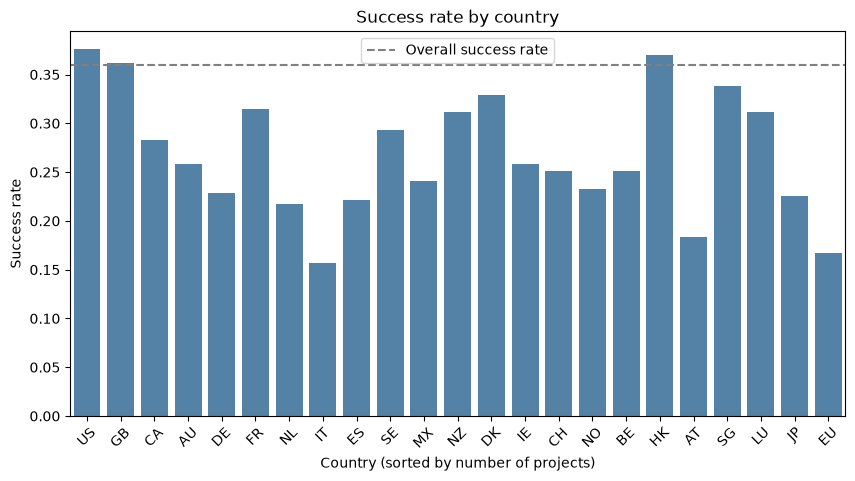

,mean,size
country,,
US,0.375811,291048
GB,0.361523,33417
CA,0.282794,14629
AU,0.258583,7777
DE,0.228760,4096
FR,0.314513,2887
NL,0.217790,2833
IT,0.156674,2802
ES,0.221223,2224


In [21]:
success_by_country = (
    kickstarter.groupby("country")["success"]
    .agg(["mean", "size"])
    .sort_values("size", ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=success_by_country.index, y=success_by_country["mean"], color="steelblue")
plt.axhline(overall_rate, color="grey", linestyle="--", label="Overall success rate")
plt.xlabel("Country (sorted by number of projects)")
plt.ylabel("Success rate")
plt.title("Success rate by country")
plt.xticks(rotation=45)
plt.legend()
plt.show()

success_by_country

**Takeaway:** Kickstarter is dominated by the **US (78% of projects)**, followed by other English-speaking countries (GB, CA, AU).
The US (38%) and GB (36%) are close to the overall success rate, while most continental European countries are clearly below it, with Italy lowest at about 16%.
Several countries have only a few hundred projects or fewer, so their rates are less reliable.

**Data fix:** 234 projects had the invalid country code `N,0"`. Since every real country in the data uses exactly one currency, we inferred the country from the currency; the 24 EUR projects are labelled `EU` because several countries use the euro.
These are corrupted records rather than only a bad country code: the 3,797 raw rows with `N,0"` are exactly the rows with a missing `usd pledged` value (checked in the First Look section), and 3,562 of them had the state `undefined` (already dropped). The 234 that remain are funded 45% of the time, above the overall rate.

### Success Rate by Launch Year and Month

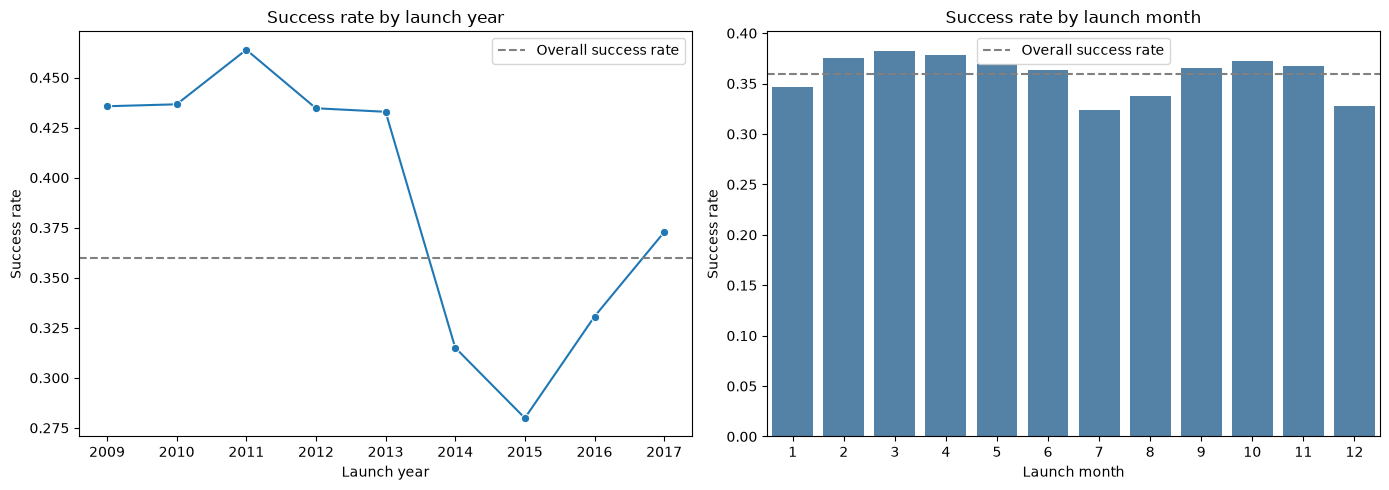

Success rate by launch month:
{1: 0.346, 2: 0.375, 3: 0.383, 4: 0.378, 5: 0.369, 6: 0.363, 7: 0.324, 8: 0.338, 9: 0.365, 10: 0.372, 11: 0.368, 12: 0.328}


,mean,size
launch_year,,
2009,0.435666,1329
2010,0.436638,10519
2011,0.463887,26237
2012,0.434662,41163
2013,0.432897,44849
2014,0.315058,66994
2015,0.279912,74920
2016,0.330649,56755
2017,0.372781,49525


In [22]:
kickstarter["launch_year"] = kickstarter["launched"].dt.year
kickstarter["launch_month"] = kickstarter["launched"].dt.month

# 2018 contains only 2 projects (data was collected in early January 2018),
# so we leave it out of the plot
success_by_year = (
    kickstarter[kickstarter["launch_year"] < 2018]
    .groupby("launch_year")["success"]
    .agg(["mean", "size"])
)
success_by_month = kickstarter.groupby("launch_month")["success"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(x=success_by_year.index, y=success_by_year["mean"], marker="o", ax=axes[0])
axes[0].axhline(
    overall_rate, color="grey", linestyle="--", label="Overall success rate"
)
axes[0].set_xlabel("Launch year")
axes[0].set_ylabel("Success rate")
axes[0].set_title("Success rate by launch year")
axes[0].legend()

sns.barplot(
    x=success_by_month.index, y=success_by_month.values, color="steelblue", ax=axes[1]
)
axes[1].axhline(
    overall_rate, color="grey", linestyle="--", label="Overall success rate"
)
axes[1].set_xlabel("Launch month")
axes[1].set_ylabel("Success rate")
axes[1].set_title("Success rate by launch month")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Success rate by launch month:")
print(success_by_month.round(3).to_dict())
success_by_year

**Takeaway (year):** The success rate was stable at about **43-46%** from 2009 to 2013, then dropped sharply in **2014 (32%)** and reached its lowest point in **2015 (28%)**, before recovering to **37% in 2017**.
At the same time, the number of projects jumped from about 45,000 in 2013 to 67,000 in 2014. A likely explanation (external context, not visible in the data) is that Kickstarter removed its manual project review in mid-2014, which made it much easier to launch projects of varying quality.
Because the success rate changes over time, we do **not** use the launch year as a model feature, and we test the model on later years separately.

**Takeaway (month):** The launch month has only a small effect: success rates range from about **32% (July)** to **38% (March)**, with July and December, typical holiday months, being the weakest.

## Class Balance

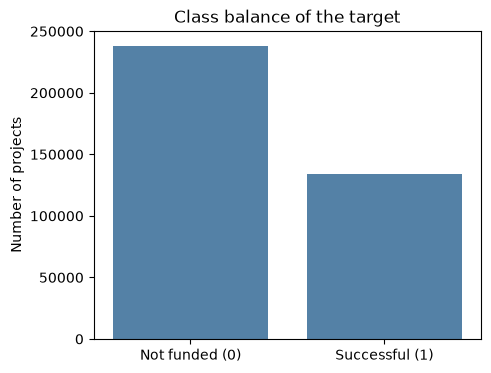

,projects,share
success,,
0,238337,0.64
1,133956,0.36


In [23]:
class_counts = kickstarter["success"].value_counts()
class_share = kickstarter["success"].value_counts(normalize=True)

plt.figure(figsize=(5, 4))
sns.barplot(
    x=["Not funded (0)", "Successful (1)"],
    y=class_counts.sort_index().values,
    color="steelblue",
)
plt.ylabel("Number of projects")
plt.title("Class balance of the target")
plt.show()

pd.DataFrame({"projects": class_counts, "share": class_share.round(3)})

**Takeaway:** After cleaning, **372,293 projects** remain: **64% not funded** (238,337) and **36% successful** (133,956).
The classes are moderately imbalanced (about 1:2), which is not extreme, so we do not need resampling techniques. It has two consequences:
- **Accuracy is misleading:** a model that always predicts "not funded" already reaches 64% accuracy.
- **Stratified split:** the train-test split must keep the 36/64 ratio in both sets.

We deliberately do **not** use class weights: they would shift all predicted probabilities upwards. Instead, the imbalance is handled by choosing the decision threshold for the yes/no label.

## Business Goal and Metric

**Stakeholder:** creators who are considering launching a project on Kickstarter.

**Value of the product:** Kickstarter uses an all-or-nothing model, so an unfunded campaign means time, effort and marketing costs without any money. An estimate **before launch** lets creators assess their chances and look at the factors linked to success (funding goal, campaign duration, category), or consider other funding options.

**Prediction:** the **probability** that a project will be successfully funded (`success = 1`), using only information available before the campaign starts.

**Evaluation metrics:**
- The creator's question is "what are my chances?", so the main output is a **probability**. We compare models with **ROC-AUC** (how well projects are ranked) and with **log loss** and the **Brier score** (how accurate the probabilities are). We also check **calibration**: a project with a predicted 40% should be funded about 40% of the time.
- For a yes/no label ("promising" or not) and for the comparison with the baseline rule, we use the **F1 score** of the successful class, with precision and recall. F1 balances two errors: a **false positive** gives a creator false confidence, a **false negative** may discourage a good idea. Accuracy is not suitable, because always predicting "not funded" already reaches 64% accuracy while its F1 score is 0.

## Feature Engineering

### Clean Project Names

Kickstarter adds **"(Canceled)"** or **"(Suspended)"** to the name of a project **after** it has been canceled or suspended, sometimes several times and in upper case.
This is target leakage hidden in a text column, so we remove these tags before building any name-based features.

**Not caught:** 4 names use the spelling "(Cancelled)", and about 120 creators renamed their project to a cancellation message (for example "Project cancelled"). This is a small leak that we accept, because the name features carry very little weight (permutation importance 0.008 for `name_words` and 0.002 for `name_length`).

In [24]:
status_tag = r"\s*\((?:canceled|suspended)\)"

has_tag = kickstarter["name"].str.contains(status_tag, regex=True, case=False, na=False)
print("Names with a status tag before cleaning:", has_tag.sum())
print(
    "Their success values:",
    kickstarter.loc[has_tag, "success"].value_counts().to_dict(),
)

kickstarter["name"] = (
    kickstarter["name"]
    .str.replace(status_tag, "", regex=True, case=False)
    .str.strip()
    .fillna("")
)

remaining_tags = (
    kickstarter["name"].str.contains(status_tag, regex=True, case=False).sum()
)
print("Names with a status tag after cleaning:", remaining_tags)

Names with a status tag before cleaning: 24135
Their success values: {0: 24135}


Names with a status tag after cleaning: 0


### Create New Features

All features below are computed **per row** from information known before launch, so they are leakage-safe and can be created before the train-test split.

In [25]:
# Funding goal on a log scale (success drops roughly linearly with the log of the goal)
kickstarter["log_goal"] = np.log1p(kickstarter["usd_goal_real"])

# Day of the week the campaign started (0 = Monday, 6 = Sunday)
kickstarter["launch_weekday"] = kickstarter["launched"].dt.dayofweek

# Length of the project name in characters and words
kickstarter["name_length"] = kickstarter["name"].str.len()
kickstarter["name_words"] = kickstarter["name"].str.split().str.len()

new_features = [
    "usd_goal_real",
    "log_goal",
    "duration_days",
    "launch_month",
    "launch_weekday",
    "name_length",
    "name_words",
]
kickstarter[new_features].describe().round(2)

,usd_goal_real,log_goal,duration_days,launch_month,launch_weekday,name_length,name_words
count,3.722930e+05,372293.00,372293.00,372293.00,372293.00,372293.00,372293.00
mean,4.572238e+04,8.64,34.17,6.43,2.42,34.15,5.62
std,1.151337e+06,1.70,12.79,3.31,1.76,16.02,2.77
min,1.000000e-02,0.01,1.00,1.00,0.00,0.00,0.00
25%,2.000000e+03,7.60,30.00,4.00,1.00,20.00,3.00
50%,5.500000e+03,8.61,30.00,6.00,2.00,33.00,5.00
75%,1.598721e+04,9.68,37.00,9.00,4.00,48.00,8.00
max,1.663614e+08,18.93,92.00,12.00,6.00,85.00,29.00


### Select Features and Target

We keep features known before launch and drop identifiers, raw text, raw dates and redundant columns:
- `currency` duplicates `country`; `goal` and `usd_goal_real` are replaced by `log_goal`.
- `main_category` is dropped because `category` (159 sub-categories) already contains it; keeping both splits their importance.
- `launch_year` is dropped: the model is meant to score **future** campaigns, and a tree model would treat every year after 2017 exactly like 2017. We check how the model holds up over time with a separate time-based test later.

In [26]:
categorical_features = ["category", "country"]
numerical_features = [
    "log_goal",
    "duration_days",
    "launch_month",
    "launch_weekday",
    "name_length",
    "name_words",
]

X = kickstarter[categorical_features + numerical_features]
y = kickstarter["success"]

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (372293, 8)
y shape: (372293,)


,category,country,log_goal,duration_days,launch_month,launch_weekday,name_length,name_words
0,Poetry,GB,7.336253,59,8,1,31,6
1,Narrative Film,US,10.308986,60,9,5,45,8
2,Narrative Film,US,10.714440,45,1,5,14,3
3,Music,US,8.517393,30,3,5,49,7
4,Film & Video,US,9.878221,56,7,5,58,8


## Train-Test Split

We hold out 20% of the projects as a test set and do not touch it until the final evaluation.
The split is **stratified** so that both sets keep the 36/64 class ratio, and `random_state` makes it reproducible.
From here on, anything we fit (encoders, scalers, models) is learned on the training set only.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Training set:", X_train.shape, "success rate:", round(y_train.mean(), 3))
print("Test set:    ", X_test.shape, "success rate:", round(y_test.mean(), 3))

Training set: (297834, 8) success rate: 0.36
Test set:     (74459, 8) success rate: 0.36


## Baseline Model

Before training any model we set a **baseline**: the simplest rule that makes a prediction.
Our EDA showed that projects with smaller funding goals succeed much more often, so the baseline predicts **success if the goal is below the median goal**.
We score it with the same 5-fold cross validation that we use for the models (the median is learned on the training part of each fold), and compare it with the trivial rule "always predict not funded".

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def classification_scores(y_true, y_pred):
    """Return accuracy, precision, recall and F1 for 0/1 predictions."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }


baseline_folds, trivial_folds = [], []
for train_idx, valid_idx in cv.split(X_train, y_train):
    fold_median = X_train["log_goal"].iloc[train_idx].median()
    y_valid_fold = y_train.iloc[valid_idx]
    y_pred_rule = (X_train["log_goal"].iloc[valid_idx] < fold_median).astype(int)
    baseline_folds.append(classification_scores(y_valid_fold, y_pred_rule))
    trivial_folds.append(classification_scores(y_valid_fold, np.zeros(len(valid_idx))))

baseline_cv = pd.DataFrame(
    {
        "Always not funded (mean)": pd.DataFrame(trivial_folds).mean(),
        "Goal below median (mean)": pd.DataFrame(baseline_folds).mean(),
        "Goal below median (std)": pd.DataFrame(baseline_folds).std(),
    }
).round(3)

median_goal = X_train["log_goal"].median()
print("Median goal in the training set (USD):", round(np.expm1(median_goal)))
baseline_cv

Median goal in the training set (USD): 5500


,Always not funded (mean),Goal below median (mean),Goal below median (std)
accuracy,0.64,0.588,0.001
precision,0.00,0.448,0.001
recall,0.00,0.619,0.003
f1,0.00,0.520,0.002


**Takeaway:** The trivial rule "always not funded" reaches the highest accuracy (64%) but never identifies a successful project, so its F1 score is **0**. This shows why accuracy is the wrong metric here.
Our baseline, "success if the goal is below the median of 5,500 USD", reaches a cross-validated **F1 score of 0.520 ± 0.002** (precision 0.448, recall 0.619). This is the score our model has to beat. The baseline only gives a yes/no label, not a probability.

## Preprocessing Pipelines

Models need numbers, so we prepare the features with a `ColumnTransformer`. Linear and tree models get different preprocessing:
- **Logistic Regression** needs one-hot encoded categories (one 0/1 column per category) and standardised numbers (mean 0, standard deviation 1).
- **Tree models** (Random Forest, Gradient Boosting) do not need scaling. Categories are encoded as integers, and Gradient Boosting treats them as categories with its native categorical support. Unknown categories become -1.
  Note: the Random Forest gets these integer codes too. It splits them as if they were ordered numbers, which slightly disadvantages it; Gradient Boosting treats them as categories.

The preprocessing is part of every model pipeline, so it is always fitted on training data only. This keeps cross validation and the final evaluation free of leakage.

In [29]:
linear_preprocessor = ColumnTransformer(
    [
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features),
    ]
)

tree_preprocessor = ColumnTransformer(
    [
        (
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-1,
            ),
            categorical_features,
        ),
        ("numerical", "passthrough", numerical_features),
    ]
)

# After the tree preprocessor, the categorical columns come first
categorical_mask = [True] * len(categorical_features) + [False] * len(
    numerical_features
)

print(
    "Columns for the linear model:",
    linear_preprocessor.fit(X_train).transform(X_train).shape[1],
)
print(
    "Columns for the tree models: ",
    tree_preprocessor.fit(X_train).transform(X_train).shape[1],
)

Columns for the linear model: 188
Columns for the tree models:  8


## Compare Models with Cross Validation

We compare three algorithms with **5-fold stratified cross validation** on the **full training set**:
- **Logistic Regression**: a simple, interpretable linear model.
- **Random Forest**: many decision trees that vote (with at least 20 projects per leaf to limit overfitting).
- **Gradient Boosting**: trees built one after another, each correcting the errors of the previous ones.

Because the main output is a **probability of success**, we compare the models with threshold-free metrics: **ROC-AUC** (how well projects are ranked), **log loss** and **Brier score** (how accurate the probabilities are; lower is better). We report the mean and the standard deviation across folds.

We do **not** use `class_weight="balanced"`: it would push all probabilities upwards, and the class imbalance is handled later by choosing the decision threshold. The test set is still untouched.

In [30]:
models = {
    "Logistic Regression": Pipeline(
        [
            ("preprocess", linear_preprocessor),
            ("model", LogisticRegression(max_iter=1000)),
        ]
    ),
    "Random Forest": Pipeline(
        [
            ("preprocess", tree_preprocessor),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=42
                ),
            ),
        ]
    ),
    "Gradient Boosting": Pipeline(
        [
            ("preprocess", tree_preprocessor),
            (
                "model",
                HistGradientBoostingClassifier(
                    categorical_features=categorical_mask, random_state=42
                ),
            ),
        ]
    ),
}

scoring = {
    "roc_auc": "roc_auc",
    "log_loss": "neg_log_loss",
    "brier": "neg_brier_score",
}

cv_rows = {}
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    row = {}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        if metric != "roc_auc":
            values = -values  # scikit-learn returns negative losses
        row[f"{metric} mean"] = values.mean()
        row[f"{metric} std"] = values.std()
    cv_rows[name] = row
    print(f"{name}: done")

cv_results = pd.DataFrame(cv_rows).T.round(4)
cv_results

Logistic Regression: done


Random Forest: done


Gradient Boosting: done


,roc_auc mean,roc_auc std,log_loss mean,log_loss std,brier mean,brier std
Logistic Regression,0.7279,0.0014,0.5752,0.0010,0.1971,0.0004
Random Forest,0.7183,0.0010,0.5813,0.0007,0.1998,0.0003
Gradient Boosting,0.7517,0.0014,0.5558,0.0010,0.1895,0.0005


**Takeaway:** **Gradient Boosting performs best** on every metric: ROC-AUC **0.752**, log loss **0.556** and Brier score **0.190**, against 0.728 / 0.575 / 0.197 for Logistic Regression and 0.718 / 0.581 / 0.200 for Random Forest.
The differences between models are about 6 times (Logistic Regression vs Random Forest) to 15 times or more (Gradient Boosting vs the others) larger than the standard deviation across folds (about 0.001), so they are very unlikely to be noise. A paired comparison of the fold differences would be the stricter test.
Logistic Regression is a reasonable second, which suggests that much of the signal is fairly simple (for example, smaller goals succeed more often). We continue with **Gradient Boosting**.
Random Forest is slightly handicapped by the ordinal category codes (see Preprocessing Pipelines), so its gap to the other models is probably a little overstated; this does not change the choice of Gradient Boosting.

## Hyperparameter Tuning

We tune Gradient Boosting with `RandomizedSearchCV`: it tries 20 random combinations of hyperparameters on the full training set and scores each one with the same 5-fold cross validation, using **log loss** as the metric.

In [31]:
param_distributions = {
    "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "model__max_iter": [100, 200, 400],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 0.1, 1.0],
}

search = RandomizedSearchCV(
    models["Gradient Boosting"],
    param_distributions,
    n_iter=20,
    scoring="neg_log_loss",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train, y_train)

best = search.best_index_
print(
    "Best CV log loss:   ",
    round(-search.best_score_, 4),
    "+/-",
    round(search.cv_results_["std_test_score"][best], 4),
)
print(
    "Default CV log loss:",
    cv_results.loc["Gradient Boosting", "log_loss mean"],
    "+/-",
    cv_results.loc["Gradient Boosting", "log_loss std"],
)
search.best_params_

Best CV log loss:    0.5555 +/- 0.001
Default CV log loss: 0.5558 +/- 0.001


{'model__min_samples_leaf': 100,
 'model__max_leaf_nodes': 31,
 'model__max_iter': 400,
 'model__learning_rate': 0.05,
 'model__l2_regularization': 1.0}

**Takeaway:** Tuning makes **no meaningful difference**: the best combination reaches a cross-validated log loss of 0.5555, against 0.5558 for the default settings, a gap well inside the fold-to-fold variation (± 0.001).
We keep the selected settings because they are no worse than the defaults.
Note: on data this large, `HistGradientBoostingClassifier` uses **early stopping** by default (10% of the training data is held out inside each fit), so `max_iter=400` is an upper limit; the final model stopped after 231 iterations. Larger improvements would have to come from better features (for example campaign content) rather than from tuning.

### Decision Threshold for the Yes/No Label

The model outputs a probability of success. To compare it with the baseline rule we also need a yes/no label ("promising" or not).
We let `TunedThresholdClassifierCV` find the threshold that maximises **F1**, again with cross validation on the training set only.
The resulting object, the tuned Gradient Boosting pipeline plus this threshold, refitted on the full training set, is our **final model**.

In [32]:
final_model = TunedThresholdClassifierCV(
    search.best_estimator_, scoring="f1", cv=cv, n_jobs=-1
)
final_model.fit(X_train, y_train)

print("F1-optimal threshold:", round(final_model.best_threshold_, 3))
print("CV F1 at this threshold:", round(final_model.best_score_, 3))

F1-optimal threshold: 0.299
CV F1 at this threshold: 0.618


**Takeaway:** The threshold that maximises F1 is **0.30**: the model labels a project as "promising" once its probability of success exceeds about 30%, with a cross-validated F1 of **0.618**.
This low threshold makes the label generous: F1 rewards finding many successful projects, so many projects get the label (we check this on the test set). For creators we therefore use the **probability** itself, grouped into chance bands, and keep the label mainly for the comparison with the baseline rule.

## Final Model and Test Evaluation

We evaluate the final model on the held-out test set.
**Note on test-set use:** test-set results were looked at once before, in a review round of an earlier version of this notebook, and the model was changed afterwards (class weights removed, `launch_year` dropped, native categorical encoding, full training set instead of a sample). These changes were driven by cross-validation and calibration principles, not by the test scores, and the cross-validation and test scores agree (ROC-AUC 0.752 in CV against 0.754 on the test set, Brier score 0.1895 against 0.189). So these scores are a fair, at most very slightly optimistic, estimate for new projects drawn from the same period. We do not change the model after this evaluation.

In [33]:
y_test_proba = final_model.predict_proba(X_test)[:, 1]
y_test_pred = final_model.predict(X_test)
y_test_baseline = (X_test["log_goal"] < median_goal).astype(int)

test_results = pd.DataFrame(
    {
        "Baseline (goal below median)": classification_scores(y_test, y_test_baseline),
        "Final model": classification_scores(y_test, y_test_pred),
    }
)
test_results.loc["share labelled successful"] = [
    y_test_baseline.mean(),
    y_test_pred.mean(),
]
test_results.loc["roc_auc", "Final model"] = roc_auc_score(y_test, y_test_proba)
test_results.loc["brier", "Final model"] = brier_score_loss(y_test, y_test_proba)
test_results.round(3)

,Baseline (goal below median),Final model
accuracy,0.591,0.641
precision,0.451,0.501
recall,0.625,0.811
f1,0.524,0.619
share labelled successful,0.499,0.583
roc_auc,NaN,0.754
brier,NaN,0.189


**Takeaway:** On the held-out test set the final model beats the baseline on every label metric: **F1 0.619** against **0.524**, precision 0.501 against 0.451 and recall 0.811 against 0.625.
- In plain numbers: of 100 projects labelled "promising", **50** are funded (simple rule: 45; a random pick: 36). The model finds **81%** of the successful projects (simple rule: 63%).
- The label is generous: it marks **58%** of all projects as promising, although only 36% are funded. This is why the probability is the more useful output for a creator.
- Because the model labels more projects than the rule (58% against 50%), the recall comparison is not like for like: labelling more projects always finds more successes. The next cell compares both at the **same share**.
- The probabilities rank projects well (**ROC-AUC 0.754**) and are accurate (**Brier score 0.189**). The test scores match the cross-validation scores, so the model does not overfit.

In [34]:
# Label the same share of test projects as the baseline rule, so that precision and
# recall can be compared like for like (used only for this comparison)
baseline_share = y_test_baseline.mean()
equal_share_threshold = np.quantile(y_test_proba, 1 - baseline_share)
y_test_equal_share = (y_test_proba >= equal_share_threshold).astype(int)

equal_share_results = pd.DataFrame(
    {
        "Baseline (goal below median)": classification_scores(y_test, y_test_baseline),
        "Final model (same share)": classification_scores(y_test, y_test_equal_share),
    }
)
equal_share_results.loc["share labelled successful"] = [
    baseline_share,
    y_test_equal_share.mean(),
]
print("Threshold that labels the same share:", round(equal_share_threshold, 3))
equal_share_results.round(3)

Threshold that labels the same share: 0.349


,Baseline (goal below median),Final model (same share)
accuracy,0.591,0.671
precision,0.451,0.530
recall,0.625,0.736
f1,0.524,0.616
share labelled successful,0.499,0.499


**Takeaway:** At a threshold of **0.349** the model labels the same share of test projects as the rule (49.9%). Compared like for like:
- Of 100 projects labelled "promising", **53** are funded (rule: 45).
- Of 100 funded projects, the model finds **74** (rule: 63). F1 is 0.616 against 0.524.

So the model is clearly better than the rule also at the same share. The recall gap is smaller than at the F1 threshold (74 vs 63 instead of 81 vs 63), because part of that gap came from labelling more projects. This threshold is used only for this comparison; the saved model keeps the F1 threshold of 0.30.

### Are the Probabilities Trustworthy?

If the model says 40%, about 40 out of 100 such projects should be funded. A **calibration plot** checks this: the closer the curve is to the diagonal, the better.
Because the probabilities are the main output for creators, we also group them into three easy-to-read **chance bands** and check how often projects in each band were actually funded.
The bands are named relative to the **average success rate of 36%**, so that a coin-flip project is not called "high". The cut-offs (25% and 50%) are fixed round numbers: a project at 49% and one at 51% fall into different bands, so creators should always see the probability first and the band second.

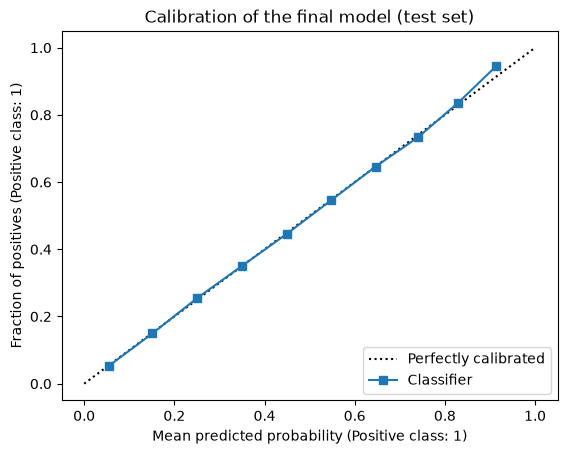

Mean predicted probability: 0.36
Actual success rate:        0.36


,projects,actual_success_rate,share_of_projects
band,,,
below average (under 25%),25151,0.136,0.338
about average (25-50%),29276,0.371,0.393
above average (50% or more),20032,0.624,0.269


In [35]:
CalibrationDisplay.from_predictions(y_test, y_test_proba, n_bins=10)
plt.title("Calibration of the final model (test set)")
plt.show()

print("Mean predicted probability:", round(y_test_proba.mean(), 3))
print("Actual success rate:       ", round(y_test.mean(), 3))

chance_band = pd.cut(
    y_test_proba,
    bins=[0, 0.25, 0.5, 1],
    labels=[
        "below average (under 25%)",
        "about average (25-50%)",
        "above average (50% or more)",
    ],
    right=False,
)
band_table = (
    pd.DataFrame({"band": chance_band, "funded": y_test.values})
    .groupby("band", observed=True)["funded"]
    .agg(projects="size", actual_success_rate="mean")
)
band_table["share_of_projects"] = band_table["projects"] / band_table["projects"].sum()
band_table.round(3)

In [36]:
# The same check in numbers: 10 equal-width probability bins
probability_bin = pd.cut(y_test_proba, bins=np.linspace(0, 1, 11))
calibration_table = (
    pd.DataFrame(
        {"bin": probability_bin, "predicted": y_test_proba, "actual": y_test.values}
    )
    .groupby("bin", observed=True)
    .agg(
        projects=("actual", "size"),
        mean_predicted=("predicted", "mean"),
        actual_rate=("actual", "mean"),
    )
)
calibration_table.round(3)

,projects,mean_predicted,actual_rate
bin,,,
"(0.0, 0.1]",8449,0.055,0.053
"(0.1, 0.2]",10860,0.151,0.150
"(0.2, 0.3]",11896,0.251,0.255
"(0.3, 0.4]",12258,0.350,0.350
"(0.4, 0.5]",10964,0.449,0.445
"(0.5, 0.6]",9170,0.549,0.547
"(0.6, 0.7]",6556,0.646,0.646
"(0.7, 0.8]",3381,0.741,0.734
"(0.8, 0.9]",907,0.829,0.836


**Takeaway:** The probabilities are **well calibrated**: the curve follows the diagonal, and the mean predicted probability (36%) equals the actual success rate (36%). Leaving out class weights made this possible. The 10-bin table shows the same in numbers: in every bin with a few hundred projects or more, the mean predicted probability and the actual success rate differ by less than one percentage point (for example 35.0% against 35.0%, and 54.9% against 54.7%). Only the top bin (90-100%) has too few projects (18) to judge.
This holds **on average over all launch years**. Per year the picture is less exact, see "Does the Model Hold Up Over Time?" below.
The three chance bands are clearly different:

| Chance band | Share of projects | Actually funded |
|---|---|---|
| Below average (under 25%) | 34% | 14% |
| About average (25-50%) | 39% | 37% |
| Above average (50% or more) | 27% | 62% |

These bands are easy to communicate and honest: an "above average" project is funded about six times in ten, not always, and "about average" projects are funded about as often as the average project (36%).

### Does the Model Hold Up Over Time?

The random split mixes all years, but the model is meant for **future** campaigns, and success rates changed a lot over time. As an extra check we train the same configuration on projects launched **before 2016** and test it on projects launched in **2016 or later**.
Note: we reuse the hyperparameters tuned on the random training set, which includes projects from 2016 and 2017, so this is not a fully clean out-of-time test. The effect is very small, because tuning changed the cross-validated log loss by only 0.0003 (0.5555 against 0.5558 with default settings).

In [37]:
launched_before_2016 = kickstarter.loc[X.index, "launch_year"] < 2016
X_early, y_early = X[launched_before_2016], y[launched_before_2016]
X_late, y_late = X[~launched_before_2016], y[~launched_before_2016]

temporal_model = TunedThresholdClassifierCV(
    search.best_estimator_, scoring="f1", cv=cv, n_jobs=-1
)
temporal_model.fit(X_early, y_early)

late_proba = temporal_model.predict_proba(X_late)[:, 1]
late_pred = temporal_model.predict(X_late)

temporal_results = pd.DataFrame(
    {
        "Random split (test set)": {
            **classification_scores(y_test, y_test_pred),
            "roc_auc": roc_auc_score(y_test, y_test_proba),
            "mean predicted probability": y_test_proba.mean(),
            "actual success rate": y_test.mean(),
        },
        "Time split (2016 onwards)": {
            **classification_scores(y_late, late_pred),
            "roc_auc": roc_auc_score(y_late, late_proba),
            "mean predicted probability": late_proba.mean(),
            "actual success rate": y_late.mean(),
        },
    }
).round(3)

print("Projects before 2016:", len(X_early), "| from 2016 onwards:", len(X_late))
temporal_results

Projects before 2016: 266011 | from 2016 onwards: 106282


,Random split (test set),Time split (2016 onwards)
accuracy,0.641,0.667
precision,0.501,0.518
recall,0.811,0.749
f1,0.619,0.612
roc_auc,0.754,0.757
mean predicted probability,0.360,0.330
actual success rate,0.360,0.350


**Takeaway:** Trained only on projects launched before 2016, the model still ranks the projects of 2016 onwards just as well (**ROC-AUC 0.757**), and its F1 score barely changes (0.612 against 0.619).
Two things do change: recall drops from **81% to 75%**, and the probabilities are slightly too low (mean 33% against an actual 35%), because success rates recovered after 2015.
So the ranking holds over time, but the exact rates drift. Before using the model on new campaigns, it should be **retrained or recalibrated on the most recent data**, for example by fitting `CalibratedClassifierCV(FrozenEstimator(model), method="isotonic")` on the newest year and checking its calibration on a later slice.

#### Calibration by Launch Year

The calibration check above pools all years. Because success rates changed over time, we also compare the mean predicted probability with the actual success rate for each launch year in the random-split test set.

In [38]:
calibration_by_year = (
    pd.DataFrame(
        {
            "launch_year": kickstarter.loc[X_test.index, "launch_year"],
            "predicted": y_test_proba,
            "actual": y_test.values,
        }
    )
    .groupby("launch_year")
    .agg(
        projects=("actual", "size"),
        mean_predicted=("predicted", "mean"),
        actual_rate=("actual", "mean"),
    )
)
calibration_by_year.round(3)

,projects,mean_predicted,actual_rate
launch_year,,,
2009,273,0.414,0.407
2010,2159,0.441,0.421
2011,5337,0.440,0.464
2012,8082,0.412,0.430
2013,8995,0.399,0.436
2014,13401,0.334,0.313
2015,14986,0.317,0.279
2016,11333,0.331,0.332
2017,9893,0.357,0.379


**Takeaway:** Per launch year the probabilities are off by up to about **4 percentage points**: too low for 2011-2013 and 2017 (for example 2013: 39.9% predicted against 43.6% actual) and too high for 2010 and 2014-2015 (2015: 31.7% against 27.9%).
Without `launch_year` the model predicts the average of all years, so it is calibrated **on average**, not for any single year. A creator today would get a chance that reflects the conditions of 2009-2017; the model should be recalibrated on the newest data before real use (see above).

## Error Analysis

We analyse the errors of the **final model** on the test set. This happens after the final evaluation and is used only to understand the model, not to change it.

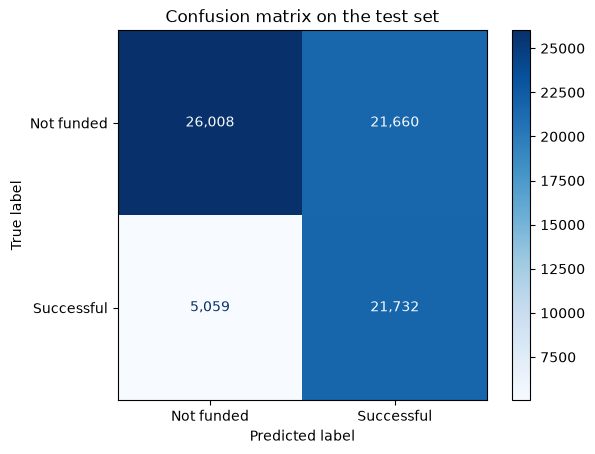

When the model says 'not funded', it is right: 0.837
Always predicting 'not funded' would be right: 0.64


In [39]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Not funded", "Successful"],
    values_format=",",
    cmap="Blues",
)
plt.title("Confusion matrix on the test set")
plt.show()

tn = ((y_test == 0) & (y_test_pred == 0)).sum()
fn = ((y_test == 1) & (y_test_pred == 0)).sum()
print("When the model says 'not funded', it is right:", round(tn / (tn + fn), 3))
print("Always predicting 'not funded' would be right:", round(1 - y_test.mean(), 3))

**Takeaway:** When the model says **"not funded"**, it is right **84%** of the time. For comparison, simply guessing "not funded" for every project would be right 64% of the time, so the warning carries real information.
The main error of the yes/no label is optimism (false positives): many projects with a probability just above 30% are labelled "promising" but are not funded. This is the price of optimising F1, and another reason to show creators the probability instead of the label.
Launch Check shows chance bands, not this label. The band works as a warning sign too: projects in the **below average** band (under 25%) were funded only **14%** of the time, against 36% on average (see the band table above).

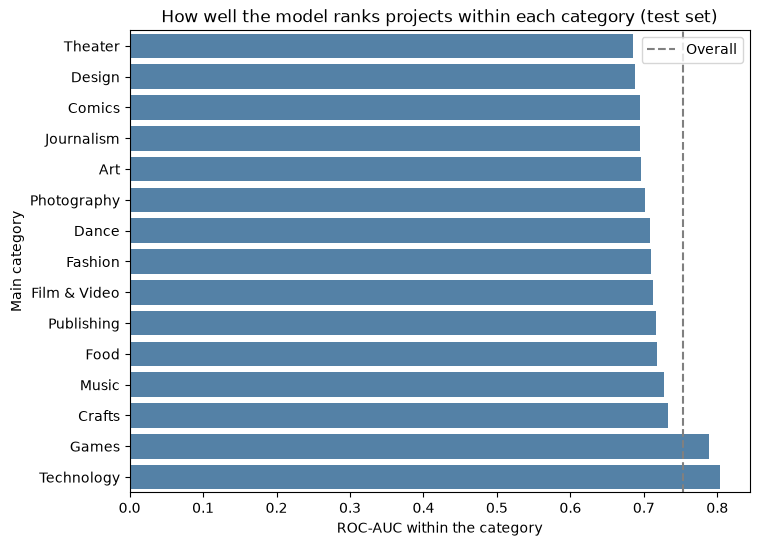

,projects,actual_rate,mean_probability,labelled_successful,roc_auc,f1
main_category,,,,,,
Theater,2199.0,0.599,0.599,0.911,0.685,0.769
Design,5923.0,0.351,0.351,0.631,0.688,0.569
Comics,2228.0,0.537,0.533,0.873,0.695,0.721
Journalism,951.0,0.222,0.207,0.234,0.695,0.419
Art,5480.0,0.406,0.413,0.735,0.697,0.619
Photography,2126.0,0.314,0.307,0.490,0.701,0.535
Dance,797.0,0.632,0.624,0.921,0.709,0.796
Fashion,4496.0,0.261,0.247,0.325,0.710,0.474
Film & Video,12555.0,0.380,0.379,0.680,0.712,0.613


In [40]:
test_results_df = X_test.copy()
test_results_df["main_category"] = kickstarter.loc[X_test.index, "main_category"]
test_results_df["actual"] = y_test
test_results_df["probability"] = y_test_proba
test_results_df["predicted"] = y_test_pred


def group_scores(group):
    """Compare actual and predicted success for one group of projects."""
    return pd.Series(
        {
            "projects": len(group),
            "actual_rate": group["actual"].mean(),
            "mean_probability": group["probability"].mean(),
            "labelled_successful": group["predicted"].mean(),
            "roc_auc": roc_auc_score(group["actual"], group["probability"]),
            "f1": f1_score(group["actual"], group["predicted"], zero_division=0),
        }
    )


errors_by_category = (
    test_results_df.groupby("main_category").apply(group_scores).sort_values("roc_auc")
)

plt.figure(figsize=(8, 6))
sns.barplot(
    x=errors_by_category["roc_auc"], y=errors_by_category.index, color="steelblue"
)
plt.axvline(
    roc_auc_score(y_test, y_test_proba), color="grey", linestyle="--", label="Overall"
)
plt.xlabel("ROC-AUC within the category")
plt.ylabel("Main category")
plt.title("How well the model ranks projects within each category (test set)")
plt.legend()
plt.show()

errors_by_category.round(3)

**Takeaway:** Within every category the **probabilities are well calibrated**: the mean predicted probability is within about 1.5 percentage points of the actual success rate (for example Dance 62% against 63%, Technology 20% against 19%).
How well the model ranks projects **within** a category varies: ROC-AUC is lowest in **Theater (0.69)**, Design and Comics, and highest in **Technology (0.80)** and **Games (0.79)**. Most are below the overall 0.754 (Technology and Games are above it), because part of the overall ranking comes from the category itself.
The yes/no label, however, is not useful within high-success categories: in Theater and Dance more than **90%** of projects are labelled promising while about 60% are funded.

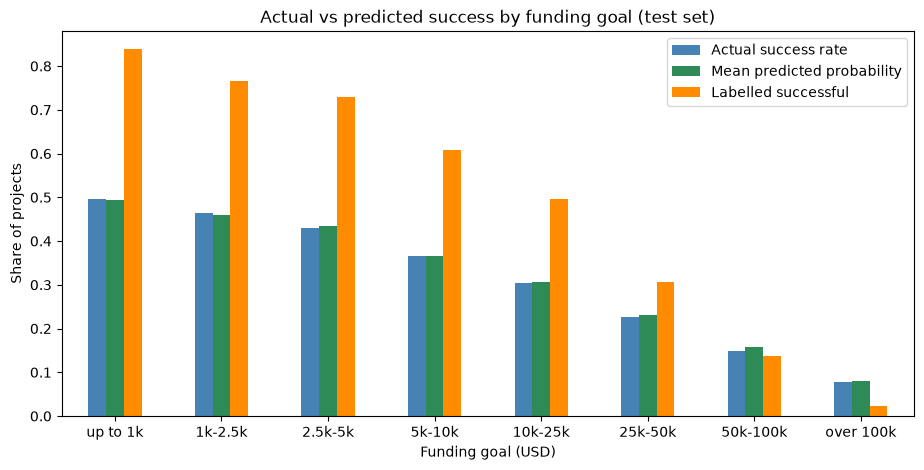

,projects,actual_rate,mean_probability,labelled_successful,roc_auc,f1
log_goal,,,,,,
up to 1k,12202.0,0.497,0.494,0.838,0.703,0.689
1k-2.5k,8587.0,0.465,0.460,0.766,0.708,0.673
2.5k-5k,11191.0,0.431,0.433,0.729,0.723,0.649
5k-10k,13736.0,0.366,0.365,0.608,0.720,0.600
10k-25k,15034.0,0.303,0.306,0.495,0.717,0.546
25k-50k,6567.0,0.227,0.230,0.305,0.717,0.449
50k-100k,3925.0,0.149,0.159,0.136,0.789,0.397
over 100k,3217.0,0.079,0.079,0.024,0.824,0.261


In [41]:
test_goal_group = pd.cut(
    np.expm1(test_results_df["log_goal"]), bins=goal_bins, labels=goal_labels
)
errors_by_goal = test_results_df.groupby(test_goal_group, observed=True).apply(
    group_scores
)

rates = errors_by_goal[
    ["actual_rate", "mean_probability", "labelled_successful"]
].rename(
    columns={
        "actual_rate": "Actual success rate",
        "mean_probability": "Mean predicted probability",
        "labelled_successful": "Labelled successful",
    }
)
rates.plot(
    kind="bar", figsize=(11, 5), rot=0, color=["steelblue", "seagreen", "darkorange"]
)
plt.xlabel("Funding goal (USD)")
plt.ylabel("Share of projects")
plt.title("Actual vs predicted success by funding goal (test set)")
plt.show()

errors_by_goal.round(3)

**Takeaway:** Across all goal ranges the **mean predicted probability matches the actual success rate** (for example 49% against 50% for goals up to 1k USD, and 8% against 8% above 100k USD).
The yes/no label, by contrast, treats the goal almost like a hard rule: it marks **84%** of projects up to 1k USD as promising (50% are funded) and only **2%** of projects above 100k USD (8% are funded).
Within the large-goal ranges the model ranks projects well (ROC-AUC 0.79 for 50k-100k and 0.82 above 100k), so the probability is informative even where the label is not.

### Feature Importance and Direction

We use **permutation importance** on a stratified sample of 20,000 test projects: shuffle one feature at a time and measure how much the **ROC-AUC** drops (with its standard deviation over 5 repeats).
Importance says how much the model relies on a feature, not whether changing it would change the outcome. **Partial dependence plots** then show the direction of the two most actionable features.

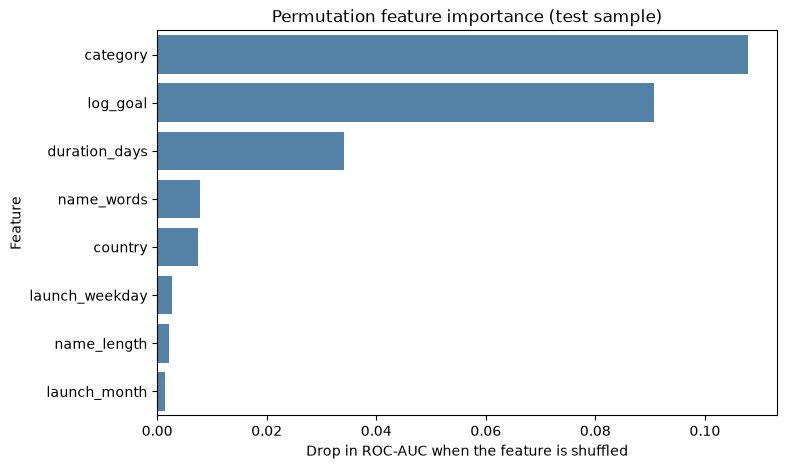

,mean,std
category,0.1078,0.0016
log_goal,0.0906,0.0030
duration_days,0.0340,0.0007
name_words,0.0079,0.0012
country,0.0075,0.0007
launch_weekday,0.0026,0.0003
name_length,0.0022,0.0004
launch_month,0.0014,0.0004


In [42]:
X_importance, _, y_importance, _ = train_test_split(
    X_test, y_test, train_size=20_000, stratify=y_test, random_state=42
)

importance = permutation_importance(
    final_model.estimator_,
    X_importance,
    y_importance,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

feature_importance = pd.DataFrame(
    {"mean": importance.importances_mean, "std": importance.importances_std},
    index=X_importance.columns,
).sort_values("mean", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=feature_importance["mean"], y=feature_importance.index, color="steelblue")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.ylabel("Feature")
plt.title("Permutation feature importance (test sample)")
plt.show()

feature_importance.round(4)

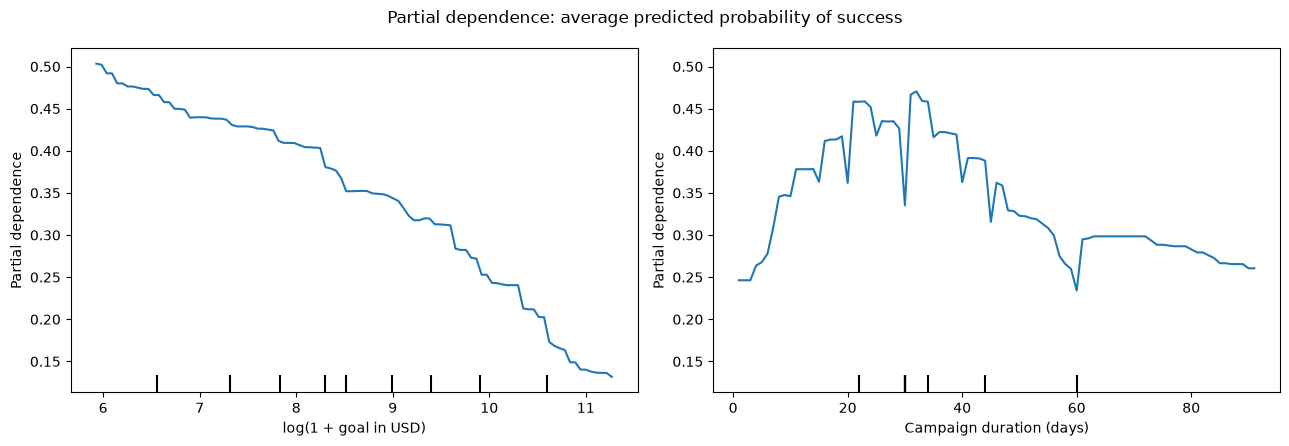

In [43]:
X_pdp, _ = train_test_split(
    X_train, train_size=5_000, stratify=y_train, random_state=42
)
# Partial dependence needs float columns for the features it varies
X_pdp = X_pdp.astype({column: float for column in numerical_features})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
PartialDependenceDisplay.from_estimator(
    final_model.estimator_,
    X_pdp,
    features=["log_goal", "duration_days"],
    ax=axes,
)
axes[0].set_xlabel("log(1 + goal in USD)")
axes[1].set_xlabel("Campaign duration (days)")
plt.suptitle("Partial dependence: average predicted probability of success")
plt.tight_layout()
plt.show()

**Takeaway:** The model relies most on the **category** (shuffling it lowers ROC-AUC by 0.108 ± 0.002) and the **funding goal** (0.091 ± 0.003), followed by the **campaign duration** (0.034). The number of words in the name and the country add a little; launch weekday, name length and launch month add almost nothing.
The partial dependence plots show the direction:
- The predicted probability falls steadily as the **goal** rises.
- For **duration**, very short campaigns (under about ten days) score low, three to six weeks scores highest, and there are sharp dips at **round-number lengths**: 15, 20, 25, 30, 35, 40, 45 and 60 days, the same pattern as in the round-number table in the EDA. Here the model has learned a marker of creator behaviour, not a lever a creator can pull.

These are the factors **most associated with success** in the data. They are not proof that changing them causes success.

## Save the Model and Score a New Project

We save the final model (preprocessing, tuned Gradient Boosting and the F1 threshold in one object) to `models/` and load it again to score a new, hypothetical project.
The saved file needs the same scikit-learn version to load reliably (printed in the setup cell).

In [44]:
model_path = ROOT / "models" / "kickstarter_success_model.joblib"
joblib.dump(final_model, model_path)

# Load the saved model and score a hypothetical new project
loaded_model = joblib.load(model_path)

new_project = pd.DataFrame(
    {
        "category": ["Tabletop Games"],
        "country": ["US"],
        "log_goal": [np.log1p(10_000)],
        "duration_days": [30],
        "launch_month": [3],
        "launch_weekday": [1],
        "name_length": [35],
        "name_words": [6],
    }
)

probability = loaded_model.predict_proba(new_project)[0, 1]
if probability < 0.25:
    band = "below average"
elif probability < 0.5:
    band = "about average"
else:
    band = "above average"

print(f"Predicted probability of success: {probability:.0%}")
print("Chance band:", band)

Predicted probability of success: 51%
Chance band: above average


**Takeaway:** The saved model can be loaded and used to score new projects. A hypothetical US tabletop game with a 10,000 USD goal and a 30-day campaign gets a probability of about **51%**, just inside the **above average** band (average: 36%).
Because the probabilities are calibrated, about half of all projects that get a probability near 51% were funded. The next cell checks a simple group of similar past projects.

In [45]:
# Similar past projects: same category, a goal of 7.5k-15k USD and exactly 30 days
similar_projects = kickstarter.query(
    "category == 'Tabletop Games' "
    "and 7_500 <= usd_goal_real <= 15_000 "
    "and duration_days == 30"
)
print("Similar projects:", len(similar_projects))
print("Share funded:    ", round(similar_projects["success"].mean(), 3))

Similar projects: 1375
Share funded:     0.433


**Takeaway:** The 1,375 tabletop games with a goal of 7.5k-15k USD and exactly 30 days were funded **43%** of the time, lower than the model's 51% for our example.
The two numbers answer different questions: this simple group ignores the launch month and weekday, the name and the country, and mixes goals from 7.5k to 15k USD, while the model uses all of these inputs. The model's probabilities are calibrated on the test set as a whole; this group is only a rough cross-check, and it shows that a single estimate should not be read too precisely.

### Why Launch Check Gives No What-If Advice

A tempting feature for a data product is a "what-if": change one input and see how the chance moves. We test this with the same hypothetical project, changing one input at a time.

In [46]:
# Score the same project with one input changed at a time (0 = Monday, 6 = Sunday)
what_if = pd.concat(
    [
        new_project,
        new_project.assign(duration_days=29),
        new_project.assign(duration_days=31),
        new_project.assign(launch_weekday=6),
    ],
    ignore_index=True,
)
what_if.index = ["as above (30 days, Tuesday)", "29 days", "31 days", "Sunday launch"]
what_if["probability"] = loaded_model.predict_proba(what_if)[:, 1].round(3)
what_if[["duration_days", "launch_weekday", "probability"]]

,duration_days,launch_weekday,probability
"as above (30 days, Tuesday)",30,1,0.511
29 days,29,1,0.717
31 days,31,1,0.621
Sunday launch,30,6,0.383


**Takeaway:** Changing the campaign length by one day, or launching on a Sunday instead of a Tuesday, moves the predicted chance by many percentage points: from 51% to **72%** for 29 days, **62%** for 31 days and **38%** for a Sunday launch. These moves follow patterns in past creator behaviour (round-number lengths, launch habits), not effects a creator could get by changing the input.
So Launch Check should show **only the estimate** and the factors it is based on, never "change X to raise your chance". If a what-if is ever added, it should be limited to the funding goal (the one input with a plausible mechanism), use a monotonic constraint (`monotonic_cst` in `HistGradientBoostingClassifier`) so the curve cannot wiggle, and carry an explicit "association, not effect" warning.